# Part 8 — Fourier basis and Fourier matrix

From TOML-MIRI *Linear Algebra for Data Science* — exploration exercises (sheet section [6]).

Topic exercises:

- **8.1** Look at the Fourier matrix
- **8.2** DFT as a change of basis
- **8.3** Speed of the FFT
- **8.4** Circulant matrices are diagonal in the Fourier basis
- **8.5** Sparsity and denoising

Each exercise keeps the sheet's own parts — **Task**, **Explore**, **Explain** — as far as the sheet defines them. Every identity carries a one-line `np.allclose` check, and every figure is printed next to the numbers behind it.

## Setup

Shared imports and helpers for the whole notebook. `fourier_matrix(N)` builds the unitary Fourier matrix from the definition, (F_N)_{ki} = ω_N^{-ki}/√N with ω_N = e^{j2π/N}, and `bin_frequencies(N, fs)` gives the frequency of every DFT bin. One BLAS thread is asked for before numpy is imported, so that the timings of 8.3 are reproducible.

In [1]:
import os

# One BLAS thread: the timings of 8.3 are then reproducible run after run.
for _var in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[_var] = "1"

import time

import numpy as np
import scipy
import scipy.linalg
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import HTML, Image as IPyImage, display

np.set_printoptions(precision=4, suppress=True)

TOL = 1e-12


def fourier_matrix(N, block=1024):
    """The unitary Fourier matrix: (F_N)_{ki} = omega_N^{-ki} / sqrt(N)."""
    F = np.empty((N, N), dtype=complex)
    i = np.arange(N)
    for s in range(0, N, block):
        e = min(s + block, N)
        k = np.arange(s, e)[:, None]
        F[s:e] = np.exp(-2j * np.pi * k * i / N) / np.sqrt(N)
    return F


def bin_frequencies(N, fs=1.0):
    """The frequency in Hz of every DFT bin, in FFT order."""
    return np.fft.fftfreq(N, d=1.0 / fs)


print("numpy", np.__version__, "| scipy", scipy.__version__, "| ipywidgets", widgets.__version__)

numpy 2.5.4 | scipy 1.18.1 | ipywidgets 8.1.9


## 8.1 — Look at the Fourier matrix

### Task

Build the Fourier matrix from its definition,

    ω_N = e^{j2π/N},      (F_N)_{ki} = ω_N^{-ki} / √N,      k, i = 0, …, N − 1,

for N = 8 and N = 64. Plot the real and the imaginary part of both matrices as heatmaps, and plot the first 8 columns of each as the sampled cosine and sine they are made of.

In [2]:
# --- Task: the Fourier matrix for N = 8 and N = 64 ------------------------
F8 = fourier_matrix(8)
F64 = fourier_matrix(64)

print("F_8 ="); print(F8)
print("F_64[0, :8] =", F64[0, :8])
print("real part of F_64 in [%.4f, %.4f], imaginary part in [%.4f, %.4f]"
      % (F64.real.min(), F64.real.max(), F64.imag.min(), F64.imag.max()))
print("column 0 (DC)      :", F64[0, :4], "...")
print("column 32 (Nyquist):", F64[32, :4], "...")
print("every column has norm 1: %s" % np.allclose(np.linalg.norm(F64, axis=0), 1.0))

# the permutation that the plain transpose gives in place of the identity
reversal = np.zeros((8, 8))
reversal[np.arange(8), (-np.arange(8)) % 8] = 1

checks = {
    "F_8 F_8^H = I": np.allclose(F8 @ F8.conj().T, np.eye(8)),
    "F_64 F_64^H = I": np.allclose(F64 @ F64.conj().T, np.eye(64)),
    "columns have norm 1": np.allclose(np.linalg.norm(F64, axis=0), 1.0),
    "col N-k = conj(col k)": np.allclose(F64[63:0:-1], np.conj(F64[1:])),
    "col 0 is constant": np.allclose(F64[0], 1.0 / np.sqrt(64)),
    "col 32 alternates": np.allclose(F64[32], (-1.0) ** np.arange(64) / 8.0),
    "F_8 F_8^T = reversal": np.allclose(F8 @ F8.T, reversal),
    "F_8 F_8^T != I (control)": not np.allclose(F8 @ F8.T, np.eye(8)),
}
for name, ok in checks.items():
    print("%-26s %s" % (name, ok))

F_8 =
[[ 0.3536+0.j      0.3536+0.j      0.3536+0.j      0.3536+0.j
   0.3536+0.j      0.3536+0.j      0.3536+0.j      0.3536+0.j    ]
 [ 0.3536+0.j      0.25  -0.25j    0.    -0.3536j -0.25  -0.25j
  -0.3536-0.j     -0.25  +0.25j   -0.    +0.3536j  0.25  +0.25j  ]
 [ 0.3536+0.j      0.    -0.3536j -0.3536-0.j     -0.    +0.3536j
   0.3536+0.j      0.    -0.3536j -0.3536-0.j     -0.    +0.3536j]
 [ 0.3536+0.j     -0.25  -0.25j   -0.    +0.3536j  0.25  -0.25j
  -0.3536-0.j      0.25  +0.25j    0.    -0.3536j -0.25  +0.25j  ]
 [ 0.3536+0.j     -0.3536-0.j      0.3536+0.j     -0.3536-0.j
   0.3536+0.j     -0.3536-0.j      0.3536+0.j     -0.3536-0.j    ]
 [ 0.3536+0.j     -0.25  +0.25j    0.    -0.3536j  0.25  +0.25j
  -0.3536-0.j      0.25  -0.25j   -0.    +0.3536j -0.25  -0.25j  ]
 [ 0.3536+0.j     -0.    +0.3536j -0.3536-0.j      0.    -0.3536j
   0.3536+0.j     -0.    +0.3536j -0.3536-0.j     -0.    -0.3536j]
 [ 0.3536+0.j      0.25  +0.25j   -0.    +0.3536j -0.25  +0.25j
  -0.3536-0.j

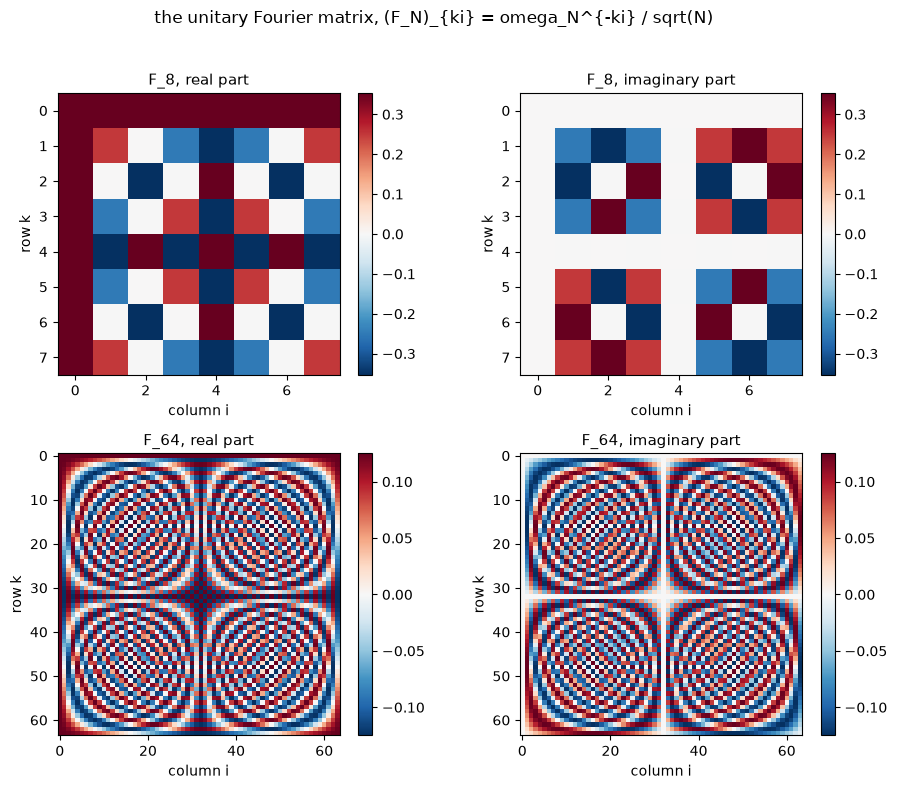

In [3]:
# --- Task: the real and imaginary parts of F_8 and F_64 as heatmaps -------
fig, axes = plt.subplots(2, 2, figsize=(9.4, 8.0))
for row, (N, F) in enumerate(((8, F8), (64, F64))):
    for col, (part, name) in enumerate(((F.real, "real"), (F.imag, "imaginary"))):
        ax = axes[row, col]
        v = float(np.abs(part).max())
        im = ax.imshow(part, cmap="RdBu_r", vmin=-v, vmax=v)
        ax.set_title("F_%d, %s part" % (N, name), fontsize=11)
        ax.set_xlabel("column i")
        ax.set_ylabel("row k")
        fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle("the unitary Fourier matrix, (F_N)_{ki} = omega_N^{-ki} / sqrt(N)")
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

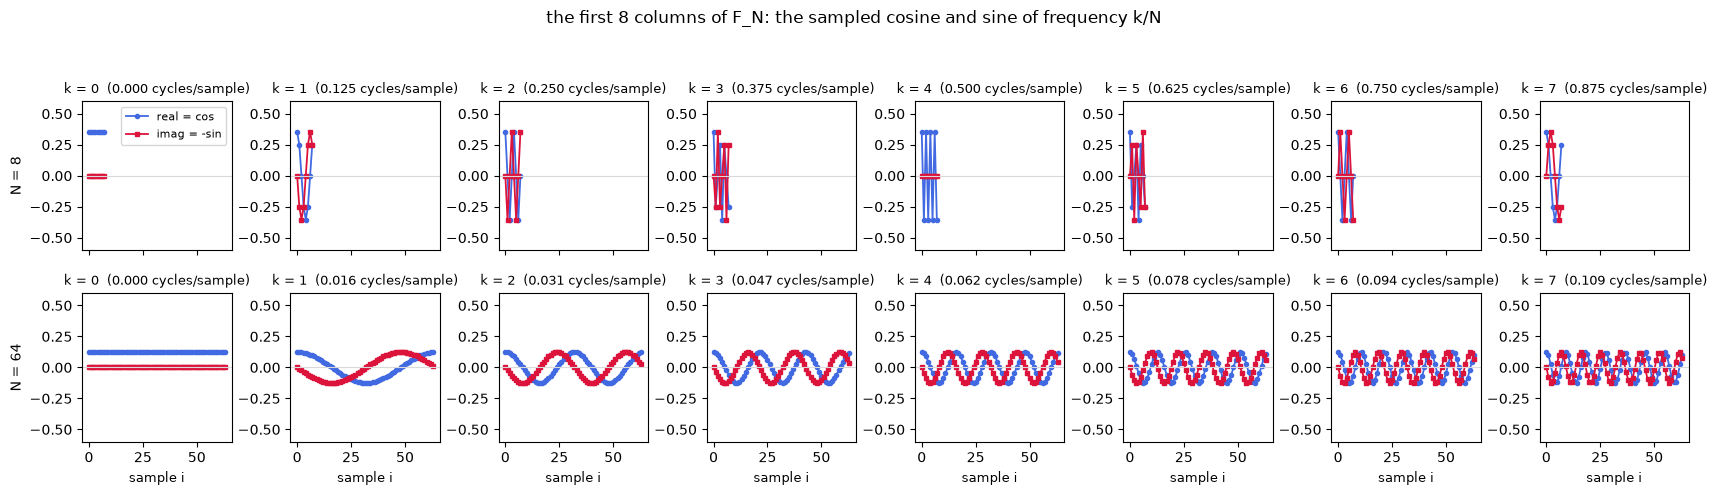

In [4]:
# --- Task: the first 8 columns as sampled cosine and sine ----------------
fig, axes = plt.subplots(2, 8, figsize=(17.0, 5.0), sharex="col")
for row, (N, F) in enumerate(((8, F8), (64, F64))):
    for k in range(8):
        ax = axes[row, k]
        i = np.arange(N)
        ax.plot(i, F[k].real, "-o", ms=3, lw=1.3, color="royalblue", label="real = cos")
        ax.plot(i, F[k].imag, "-s", ms=3, lw=1.3, color="crimson", label="imag = -sin")
        ax.set_title("k = %d  (%.3f cycles/sample)" % (k, k / N), fontsize=9)
        ax.axhline(0.0, color="0.85", lw=0.8)
        ax.set_ylim(-0.6, 0.6)
        if row == 1:
            ax.set_xlabel("sample i", fontsize=9)
        if k == 0:
            ax.set_ylabel("N = %d" % N, fontsize=10)
        if row == 0 and k == 0:
            ax.legend(fontsize=8, loc="upper right")
fig.suptitle("the first 8 columns of F_N: the sampled cosine and sine of frequency k/N")
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

### Explain

**Why F_N F_N^H = I.** Column k of F_N is the sampled complex exponential (1/√N)e^{-j2πki/N}, and the inner product of columns k and ℓ is (1/N) Σ_{i=0}^{N−1} e^{j2πi(k−ℓ)/N}, a geometric series that is N for k = ℓ and 0 for k ≠ ℓ. The columns are therefore orthonormal, F_N is unitary, and it changes the coordinates of a vector without changing its norm.

**Why the conjugate transpose.** The inner product on C^N is x^H y = conj(x)ᵀ y, and that is the inner product in which the columns of F_N are orthogonal. With the plain transpose the product F_N F_N^T is not the identity but the permutation that reverses the samples, (F_N F_N^T x)_k = x_{(N−k) mod N}: the transpose undoes the change of basis by turning the signal backwards instead of by leaving it alone, so an inverse transform built with it would be wrong.

**Which columns are low and which are high.** Column k holds k/N cycles per sample: column 0 is constant (the DC component), column 1 is the slowest oscillation, and the highest frequency sits at k = N/2, the Nyquist column alternating ±1/√N. The negative frequencies mirror the positive ones, F_{N−k} = conj(F_k), so the columns N−1, N−2, … carry the same physical frequencies as columns 1, 2, … with the opposite sign of rotation.

## 8.2 — DFT as a change of basis

### Task

Compute x̂ = F_N x for a random x and compare it with np.fft.fft(x), and check the inverse transform of the sheet,

    x_i = (1/N) Σ_{k=0}^{N−1} x̂_k e^{j2πki/N},

which for the unitary spectrum of this notebook is x = F_N^H x̂. The unitary F_N carries the 1/√N that the DFT of the sheet leaves out.

In [5]:
# --- Task: the DFT as a change of basis ----------------------------------
rng = np.random.default_rng(7)
N82 = 32
x82 = rng.standard_normal(N82) + 1j * rng.standard_normal(N82)
F82 = fourier_matrix(N82)
xhat82 = F82 @ x82
fft82 = np.fft.fft(x82)

k = np.arange(N82)[:, None]
i = np.arange(N82)[None, :]
back82 = (np.exp(2j * np.pi * k * i / N82) @ fft82) / N82

print("||x||_2 = %.6f   ||F x||_2 = %.6f   ||fft(x)||_2 = %.6f"
      % (np.linalg.norm(x82), np.linalg.norm(xhat82), np.linalg.norm(fft82)))
print("max |F x - fft(x)/sqrt(N)|            = %.3e"
      % np.abs(xhat82 - fft82 / np.sqrt(N82)).max())
print("max |F x - fft(x, norm='ortho')|      = %.3e"
      % np.abs(xhat82 - np.fft.fft(x82, norm="ortho")).max())
print("max |x - (1/N) sum_k fft(x)_k e^{j2pi k i/N}| = %.3e"
      % np.abs(x82 - back82).max())

checks = {
    "F x = fft(x)/sqrt(N)": np.allclose(xhat82, fft82 / np.sqrt(N82)),
    "F x = fft(x, norm='ortho')": np.allclose(xhat82, np.fft.fft(x82, norm="ortho")),
    "Parseval ||x|| = ||F x||": np.allclose(np.linalg.norm(x82), np.linalg.norm(xhat82)),
    "F^H (F x) = x": np.allclose(F82.conj().T @ xhat82, x82),
    "inverse of the sheet": np.allclose(back82, x82),
    "fft(x) = sqrt(N) F x": np.allclose(fft82, np.sqrt(N82) * xhat82),
}
for name, ok in checks.items():
    print("%-28s %s" % (name, ok))

||x||_2 = 7.138895   ||F x||_2 = 7.138895   ||fft(x)||_2 = 40.383688
max |F x - fft(x)/sqrt(N)|            = 1.627e-14
max |F x - fft(x, norm='ortho')|      = 1.627e-14
max |x - (1/N) sum_k fft(x)_k e^{j2pi k i/N}| = 1.154e-14
F x = fft(x)/sqrt(N)         True
F x = fft(x, norm='ortho')   True
Parseval ||x|| = ||F x||     True
F^H (F x) = x                True
inverse of the sheet         True
fft(x) = sqrt(N) F x         True


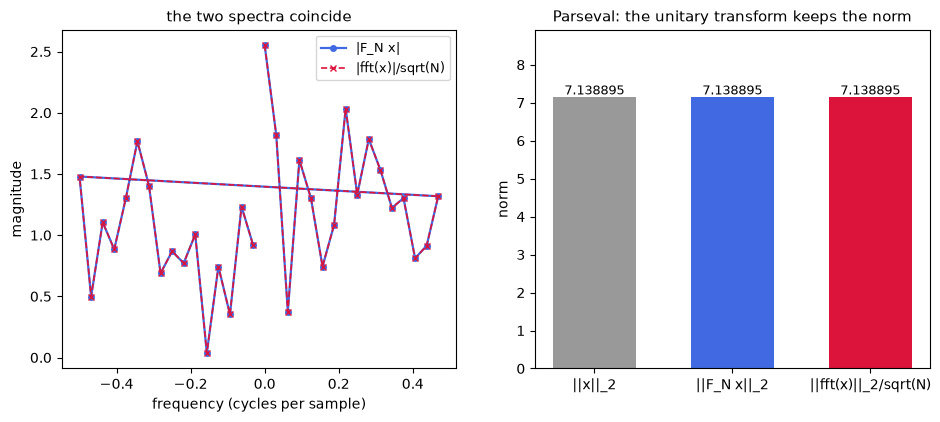

In [6]:
# --- Task: the spectrum and the norms -----------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.4))
freqs82 = bin_frequencies(N82)

ax = axes[0]
ax.plot(freqs82, np.abs(xhat82), "-o", ms=4, lw=1.6, color="royalblue", label="|F_N x|")
ax.plot(freqs82, np.abs(fft82) / np.sqrt(N82), "--x", ms=5, lw=1.2,
        color="crimson", label="|fft(x)|/sqrt(N)")
ax.set_xlabel("frequency (cycles per sample)")
ax.set_ylabel("magnitude")
ax.set_title("the two spectra coincide", fontsize=11)
ax.legend(fontsize=9)

ax = axes[1]
names = ("||x||_2", "||F_N x||_2", "||fft(x)||_2/sqrt(N)")
vals = (np.linalg.norm(x82), np.linalg.norm(xhat82),
        np.linalg.norm(fft82) / np.sqrt(N82))
ax.bar(names, vals, color=("0.6", "royalblue", "crimson"), width=0.6)
for n, v in zip(names, vals):
    ax.text(n, v, "%.6f" % v, ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, max(vals) * 1.25)
ax.set_ylabel("norm")
ax.set_title("Parseval: the unitary transform keeps the norm", fontsize=11)
plt.show()

### Explain

**The scaling factor.** The DFT of the sheet is x̂_k = Σ_{i=0}^{N−1} x_i e^{-j2πki/N}, which is exactly what np.fft.fft(x) computes. The unitary matrix F_N carries an extra 1/√N, so F_N x = np.fft.fft(x)/√N, and numpy's own unitary option, np.fft.fft(x, norm="ortho"), divides by √N as well, so with that option the two agree to machine precision. The inverse of the sheet, x_i = (1/N) Σ_{k=0}^{N−1} x̂_k e^{j2πki/N}, is the unnormalised spectrum put back with np.fft.ifft; with the unitary F_N the same inverse is simply x = F_N^H x̂.

**Parseval.** Because F_N is unitary it preserves the norm, ‖x̂‖₂ = ‖F_N x‖₂ = ‖x‖₂: the unitary form of Parseval's identity. The unnormalised DFT of numpy has ‖fft(x)‖₂ = √N ‖x‖₂ instead, so its spectrum has to be divided by √N before the two norms can be compared.

**What the transform does.** x̂ = F_N x is the change of basis: x̂ collects the amplitudes of the sampled complex exponentials that make up the signal, and x = F_N^H x̂ puts them back because F_N^H F_N = I. Being unitary, the DFT is a rotation of C^N, and the price of that rotation is what 8.3 measures.

## 8.3 — Speed of the FFT

### Task

Time the matrix–vector product F_N x against np.fft.fft(x) for N = 2⁶, …, 2¹⁴ and plot both on a log–log scale.

In [7]:
# --- Task: matrix-vector against FFT, for N = 2^6 ... 2^14 ----------------
def time_matvec(N, x, reps=3, block=1024):
    """The time of F_N x, one block of rows at a time.

    A dense 16384 x 16384 complex matrix would need 4.3 GB, so the rows of
    F_N are built in blocks and only the matrix-vector product is timed.
    """
    i = np.arange(N)
    y = np.zeros(N, dtype=complex)
    best = np.inf
    for _ in range(reps):
        total = 0.0
        for s in range(0, N, block):
            e = min(s + block, N)
            k = np.arange(s, e)[:, None]
            Fb = np.exp(-2j * np.pi * k * i / N) / np.sqrt(N)
            t0 = time.perf_counter()
            y[s:e] = Fb @ x
            total += time.perf_counter() - t0
        best = min(best, total)
    return best, y


def time_min(fn, reps):
    """The smallest time of reps calls of fn."""
    best = np.inf
    for _ in range(reps):
        t0 = time.perf_counter()
        fn()
        best = min(best, time.perf_counter() - t0)
    return best


rng = np.random.default_rng(21)
NS = 2 ** np.arange(6, 15)
t_mv, t_fft = [], []
for N in NS:
    x = rng.standard_normal(N) + 1j * rng.standard_normal(N)
    tmv, _ = time_matvec(N, x, reps=3)
    np.fft.fft(x)
    est = time_min(lambda: np.fft.fft(x), 3)
    tfft = time_min(lambda: np.fft.fft(x), int(np.clip(0.02 / est, 3, 5000)))
    t_mv.append(tmv)
    t_fft.append(tfft)
    print("N = %6d   F_N x %.3e s   fft %.3e s   ratio %8.1f   N/log2(N) %8.1f"
          % (N, tmv, tfft, tmv / tfft, N / np.log2(N)))

slope_mv = np.polyfit(np.log(NS[-4:]), np.log(t_mv[-4:]), 1)[0]
slope_fft = np.polyfit(np.log(NS[-4:]), np.log(t_fft[-4:]), 1)[0]
ratio = np.array(t_mv) / np.array(t_fft)
slope_ratio = np.polyfit(np.log(NS[-4:]), np.log(ratio[-4:]), 1)[0]
print("slope of F_N x on the four largest N: %.3f   (O(N^2))" % slope_mv)
print("slope of fft on the four largest N:    %.3f   (O(N log2 N))" % slope_fft)
print("slope of the ratio on the four largest N: %.3f" % slope_ratio)

x_check = rng.standard_normal(64) + 1j * rng.standard_normal(64)
_, y_blk = time_matvec(64, x_check, reps=1)
checks = {
    "blocked F_N x = fft(x)/sqrt(N)": np.allclose(y_blk, np.fft.fft(x_check) / 8.0),
    "dense F_N x = blocked F_N x": np.allclose(fourier_matrix(64) @ x_check, y_blk),
    "slope of F_N x ~ 2": 1.9 <= slope_mv <= 2.1,
    "slope of fft ~ 1": 0.9 <= slope_fft <= 1.15,
    "ratio grows like N/log2 N": 0.8 <= slope_ratio <= 1.2,
}
for name, ok in checks.items():
    print("%-30s %s" % (name, ok))

N =     64   F_N x 1.881e-06 s   fft 2.350e-06 s   ratio      0.8   N/log2(N)     10.7
N =    128   F_N x 4.961e-06 s   fft 2.750e-06 s   ratio      1.8   N/log2(N)     18.3
N =    256   F_N x 1.670e-05 s   fft 3.230e-06 s   ratio      5.2   N/log2(N)     32.0
N =    512   F_N x 5.199e-05 s   fft 3.980e-06 s   ratio     13.1   N/log2(N)     56.9
N =   1024   F_N x 2.250e-04 s   fft 6.020e-06 s   ratio     37.4   N/log2(N)    102.4
N =   2048   F_N x 1.547e-03 s   fft 1.010e-05 s   ratio    153.1   N/log2(N)    186.2
N =   4096   F_N x 7.732e-03 s   fft 1.949e-05 s   ratio    396.7   N/log2(N)    341.3
N =   8192   F_N x 2.797e-02 s   fft 4.036e-05 s   ratio    693.0   N/log2(N)    630.2
N =  16384   F_N x 1.132e-01 s   fft 8.102e-05 s   ratio   1397.3   N/log2(N)   1170.3
slope of F_N x on the four largest N: 2.044   (O(N^2))
slope of fft on the four largest N:    1.006   (O(N log2 N))
slope of the ratio on the four largest N: 1.037
blocked F_N x = fft(x)/sqrt(N) True
dense F_N x = blo

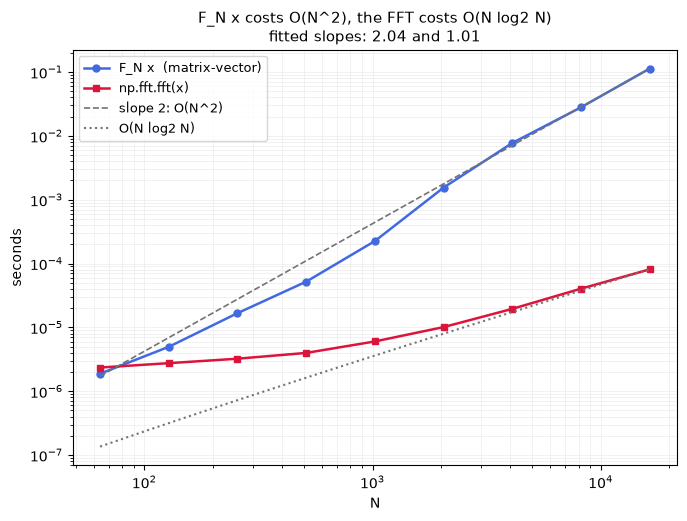

In [8]:
# --- Task: the two costs on a log-log scale -------------------------------
fig, ax = plt.subplots(figsize=(7.8, 5.4))
ax.loglog(NS, t_mv, "-o", color="royalblue", lw=1.8, ms=5, label="F_N x  (matrix-vector)")
ax.loglog(NS, t_fft, "-s", color="crimson", lw=1.8, ms=5, label="np.fft.fft(x)")

n_ref = np.logspace(np.log10(NS[0]), np.log10(NS[-1]), 60)
ax.loglog(n_ref, t_mv[-1] * (n_ref / NS[-1]) ** 2, "--", color="0.45", lw=1.2,
          label="slope 2: O(N^2)")
ax.loglog(n_ref, t_fft[-1] * (n_ref / NS[-1]) * np.log2(n_ref) / np.log2(NS[-1]),
          ":", color="0.45", lw=1.5, label="O(N log2 N)")

ax.set_xlabel("N")
ax.set_ylabel("seconds")
ax.set_title("F_N x costs O(N^2), the FFT costs O(N log2 N)\n"
             "fitted slopes: %.2f and %.2f" % (slope_mv, slope_fft), fontsize=11)
ax.grid(True, which="both", lw=0.4, color="0.9")
ax.legend(fontsize=9, loc="upper left")
plt.show()

### Explain

**Do the slopes match the costs of [6.3.2]?** The matrix–vector product F_N x does N² complex multiplications, and the measured curve has slope ≈ 2.0 on the four largest sizes — the O(N²) of the sheet. The FFT touches only O(log N) times every sample, so it costs O(N log₂ N); the measured slope is ≈ 1.0, and the slope of N log₂ N on a log–log plot is 1 + 1/log₂ N ≈ 1.07 at N = 2¹⁴, which the measurement reaches.

**Why the FFT curve looks flat on the left.** For small N a fixed overhead of a few µs per call is more than the arithmetic itself, so the first points of the FFT curve lie below the trend line. The slope is therefore fitted on the four largest sizes, where the FFT is compute bound.

**How large the win is.** The ratio of the two costs grows like N/log₂ N (measured slope ≈ 1.0) and is already above 1300 at N = 2¹⁴, where N/log₂ N = 1170. The quadratic cost of the dense product and the nearly linear cost of the FFT are two statements about the same operator: F_N x is the same vector however it is computed.

## 8.4 — Circulant matrices are diagonal in the Fourier basis

### Task

Build a random circulant matrix C = scipy.linalg.circulant(h), compute F_N C F_N^H and show it as a heatmap. The sheet also asks for the convolution picture,

    C = F_N^H Λ F_N,      Cx = h ⊛ x = F_N^H Λ F_N x,      λ_k = Σ_{t=0}^{N−1} h_t ω_N^{−kt}.

In [9]:
# --- Task: a circulant matrix is diagonal in the Fourier basis -------------
rng = np.random.default_rng(3)
N84 = 32
h84 = rng.standard_normal(N84)
C84 = scipy.linalg.circulant(h84)
F84 = fourier_matrix(N84)
D84 = F84 @ C84 @ F84.conj().T
lam84 = np.fft.fft(h84)
x84 = rng.standard_normal(N84)
conv84 = np.fft.ifft(np.fft.fft(h84) * np.fft.fft(x84))

print("first row of C    :", C84[0, :6], "...")
print("first column of C :", C84[:6, 0], "...")
print("lambda = fft(h)   :", lam84[:6], "...")
print("largest entry off the diagonal of F C F^H = %.3e"
      % np.abs(D84 - np.diag(np.diag(D84))).max())
print("dense C x costs N^2 = %d multiply-adds, three FFTs cost 3 N log2 N = %d"
      % (N84 ** 2, int(3 * N84 * np.log2(N84))))

checks = {
    "F C F^H is diagonal": np.allclose(D84, np.diag(np.diag(D84))),
    "diagonal = DFT of h": np.allclose(np.diag(D84), lam84),
    "diagonal = sqrt(N) F h": np.allclose(np.diag(D84), np.sqrt(N84) * (F84 @ h84)),
    "C = F^H Lambda F": np.allclose(C84, F84.conj().T @ np.diag(lam84) @ F84),
    "conj(F[:,k]) eigenvector": np.allclose(C84 @ np.conj(F84[:, 5]),
                                            lam84[5] * np.conj(F84[:, 5])),
    "two FFTs + one product = Cx": np.allclose(conv84, C84 @ x84),
}
for name, ok in checks.items():
    print("%-28s %s" % (name, ok))

first row of C    : [ 2.0409 -0.2917 -0.8865  1.0023 -0.2436 -0.2696] ...
first column of C : [ 2.0409 -2.5557  0.4181 -0.5678 -0.4526 -0.2156] ...
lambda = fft(h)   : [ 0.5661+0.j     -1.9363+5.4067j -3.8514+1.9114j  3.4601+4.9424j
  1.9861-6.5535j -3.7025-1.7629j] ...
largest entry off the diagonal of F C F^H = 2.718e-14
dense C x costs N^2 = 1024 multiply-adds, three FFTs cost 3 N log2 N = 480
F C F^H is diagonal          True
diagonal = DFT of h          True
diagonal = sqrt(N) F h       True
C = F^H Lambda F             True
conj(F[:,k]) eigenvector     True
two FFTs + one product = Cx  True


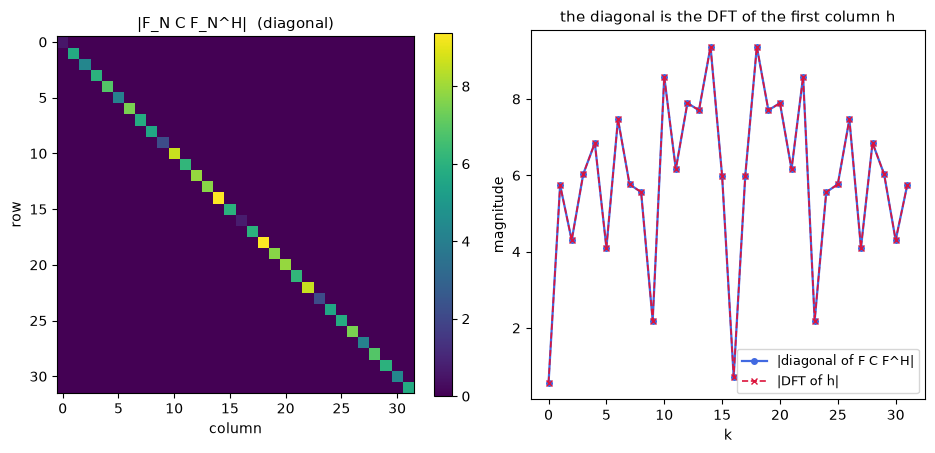

In [10]:
# --- Task: the heatmap of F C F^H and its diagonal -------------------------
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.8))

ax = axes[0]
im = ax.imshow(np.abs(D84), cmap="viridis")
ax.set_title("|F_N C F_N^H|  (diagonal)", fontsize=11)
ax.set_xlabel("column")
ax.set_ylabel("row")
fig.colorbar(im, ax=ax, fraction=0.046)

ax = axes[1]
k84 = np.arange(N84)
ax.plot(k84, np.abs(np.diag(D84)), "-o", color="royalblue", ms=4, lw=1.6,
        label="|diagonal of F C F^H|")
ax.plot(k84, np.abs(lam84), "--x", color="crimson", ms=5, lw=1.2,
        label="|DFT of h|")
ax.set_xlabel("k")
ax.set_ylabel("magnitude")
ax.set_title("the diagonal is the DFT of the first column h", fontsize=11)
ax.legend(fontsize=9)
plt.show()

### Explain

**Why F_N C F_N^H is diagonal.** A circulant matrix is a sum of powers of the shift matrix, and the sampled complex exponentials are the eigenvectors of a shift: the vector (1, ω^k, ω^{2k}, …) is multiplied by a one-sample shift by the factor ω^k. Being built from such shifts, C has the same eigenvectors, with eigenvalue λ_k = Σ_{t=0}^{N−1} h_t ω_N^{−kt}. Those eigenvectors are the conjugated columns of F_N, so writing C in its own eigenbasis gives F_N C F_N^H = Λ, a diagonal matrix — the decomposition the sheet writes as C = F_N^H Λ F_N.

**The diagonal is the DFT of h.** λ_k = Σ_{t=0}^{N−1} h_t ω_N^{−kt} is exactly the k-th DFT coefficient of the first column h, which is why the diagonal of F_N C F_N^H and np.fft.fft(h) are the same numbers, and why the unitary version of that spectrum is √N F_N h.

**The convolution.** The first column of C is h, so (Cx)_i = Σ_{j=0}^{N−1} h_{(i−j) mod N} x_j is the circular convolution h ⊛ x. In the Fourier basis the convolution becomes a product, Cx = F_N^H Λ F_N x, and it is computed with two forward FFTs (one for h, one for x), one element-wise product and one inverse FFT: a few N log₂ N operations instead of the N² multiply-adds of the dense product.

## 8.5 — Sparsity and denoising

### Task

Reproduce Example 6.2: the signal

    f(t) = sin(2π·50 t) + sin(2π·120 t) + ε(t),      ε(t) ~ N(0, σ²),

sampled at 1000 Hz for one second. Plot the power spectrum, keep the k largest coefficients and invert the transform. The picture uses k = 4 and σ = 0.5; k and σ are on sliders in the Explore.

In [11]:
# --- Task: Example 6.2, the power spectrum and the hard threshold ---------
FS85 = 1000.0
N85 = 1000
SIGMA85 = 0.5
K85 = 4

rng = np.random.default_rng(11)
t85 = np.arange(N85) / FS85
clean85 = np.sin(2 * np.pi * 50 * t85) + np.sin(2 * np.pi * 120 * t85)
noise85 = rng.standard_normal(N85)
noisy85 = clean85 + SIGMA85 * noise85
F85 = fourier_matrix(N85)
freqs85 = bin_frequencies(N85, FS85)


def hard_threshold(x, k):
    """Keep the k largest coefficients of the unitary DFT of x and invert."""
    xhat = F85 @ x
    power = np.abs(xhat) ** 2
    order = np.argsort(power)[::-1]
    keep = order[:k]
    xhat_kept = np.zeros(len(x), dtype=complex)
    xhat_kept[keep] = xhat[keep]
    return F85.conj().T @ xhat_kept, keep, power


def top_energy(power, k=4):
    """The share of the total power carried by the k largest coefficients."""
    return np.sort(power)[::-1][:k].sum() / power.sum()


den85, keep85, power85 = hard_threshold(noisy85, K85)
clean_hat85 = F85 @ clean85
noise_hat85 = F85 @ (SIGMA85 * noise85)

print("kept bins       =", sorted(keep85.tolist()))
print("kept frequencies =", sorted(np.round(freqs85[keep85], 1).tolist()), "Hz")
print("||denoised - clean|| / ||clean|| = %.4f"
      % (np.linalg.norm(den85 - clean85) / np.linalg.norm(clean85)))
print("energy kept by the %d largest bins = %.4f of the total"
      % (K85, top_energy(power85)))
print("nonzero coefficients of the clean signal: %d of %d"
      % (np.sum(np.abs(clean_hat85) > 1e-9), N85))
print("energy in the 4 largest bins: clean %.4f, noise %.4f"
      % (top_energy(np.abs(clean_hat85) ** 2), top_energy(np.abs(noise_hat85) ** 2)))
print("max/mean of |spectrum|: clean %.1f, noise %.2f"
      % (np.abs(clean_hat85).max() / np.abs(clean_hat85).mean(),
         np.abs(noise_hat85).max() / np.abs(noise_hat85).mean()))
print("energy: clean %.1f, noise %.1f"
      % (np.sum(np.abs(clean_hat85) ** 2), np.sum(np.abs(noise_hat85) ** 2)))

checks = {
    "clean signal is 4-sparse": np.sum(np.abs(clean_hat85) > 1e-9) == 4,
    "clean energy sits in 4 bins": top_energy(np.abs(clean_hat85) ** 2) > 0.999,
    "noise energy is spread": top_energy(np.abs(noise_hat85) ** 2) < 0.05,
    "kept bins are the two tones": sorted(keep85.tolist()) == [50, 120, 880, 950],
    "denoised ~ clean": np.linalg.norm(den85 - clean85) / np.linalg.norm(clean85) < 0.1,
    "Parseval on the noisy signal": np.allclose(np.linalg.norm(noisy85),
                                               np.linalg.norm(F85 @ noisy85)),
}
for name, ok in checks.items():
    print("%-30s %s" % (name, ok))

kept bins       = [50, 120, 880, 950]
kept frequencies = [-120.0, -50.0, 50.0, 120.0] Hz
||denoised - clean|| / ||clean|| = 0.0542
energy kept by the 4 largest bins = 0.7884 of the total
nonzero coefficients of the clean signal: 4 of 1000
energy in the 4 largest bins: clean 1.0000, noise 0.0209
max/mean of |spectrum|: clean 250.0, noise 2.64
energy: clean 1000.0, noise 250.5
clean signal is 4-sparse       True
clean energy sits in 4 bins    True
noise energy is spread         True
kept bins are the two tones    True
denoised ~ clean               True
Parseval on the noisy signal   True


/home/joelG/TOML/portfolio-LA/.pixi/envs/mcp/lib/python3.12/site-packages/matplotlib/cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/joelG/TOML/portfolio-LA/.pixi/envs/mcp/lib/python3.12/site-packages/matplotlib/cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


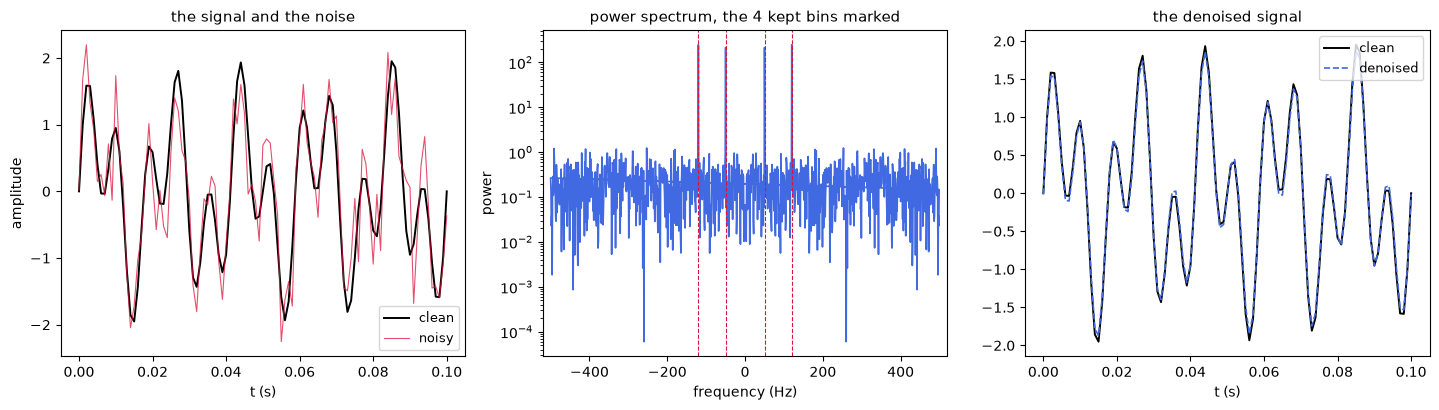

In [12]:
# --- Task: the signal, its power spectrum and the denoised signal ---------
def denoising_figure(x, k, den, keep, power, ref_a=None, ref_c=None,
                     label_a="noisy", label_c="clean"):
    """The three panels of Example 6.2 for the signal x."""
    fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2))
    win = (t85 >= 0.0) & (t85 <= 0.1)

    ax = axes[0]
    if ref_a is not None:
        ax.plot(t85[win], ref_a[win], color="black", lw=1.4, label=label_c)
    ax.plot(t85[win], x[win], color="crimson", lw=0.8, alpha=0.75, label=label_a)
    ax.set_xlabel("t (s)")
    ax.set_ylabel("amplitude")
    ax.set_title("the signal and the noise", fontsize=11)
    ax.legend(fontsize=9)

    ax = axes[1]
    ax.semilogy(freqs85, power, color="royalblue", lw=1.2)
    for b in keep:
        ax.axvline(freqs85[b], color="crimson", ls="--", lw=0.8)
    ax.set_xlabel("frequency (Hz)")
    ax.set_ylabel("power")
    ax.set_xlim(-520, 520)
    ax.set_title("power spectrum, the %d kept bins marked" % k, fontsize=11)

    ax = axes[2]
    if ref_c is not None:
        ax.plot(t85[win], ref_c[win], color="black", lw=1.4, label=label_c)
    ax.plot(t85[win], den[win], color="royalblue", lw=1.2, ls="--", label="denoised")
    ax.set_xlabel("t (s)")
    ax.set_title("the denoised signal", fontsize=11)
    ax.legend(fontsize=9)

    fig.tight_layout()
    return fig


fig = denoising_figure(noisy85, K85, den85, keep85, power85,
                        ref_a=clean85, ref_c=clean85)
plt.show()

### Explore

Vary k and the noise level σ, and repeat with pure white noise.

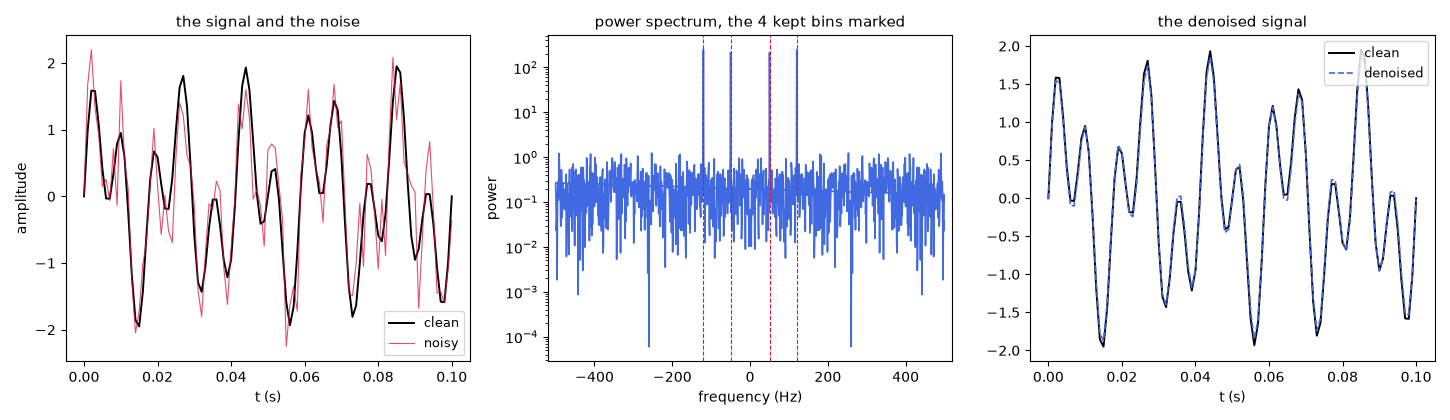

In [13]:
# --- Explore: vary k and the noise level, and try pure white noise -------
import io

k_slider = widgets.IntSlider(value=K85, min=1, max=60, step=1, description="k",
                             continuous_update=False,
                             layout=widgets.Layout(width="300px"))
sigma_slider = widgets.FloatSlider(value=SIGMA85, min=0.0, max=1.5, step=0.05,
                                   description="sigma", continuous_update=False,
                                   layout=widgets.Layout(width="300px"))
white_box = widgets.Checkbox(value=False, description="pure white noise",
                             layout=widgets.Layout(width="300px"))
_handles = {}


def show(key, obj):
    """Display obj once, then update that same output in place."""
    if key in _handles:
        _handles[key].update(obj)
    else:
        _handles[key] = display(obj, display_id="8.5 " + key)


def refresh(*_):
    k = int(k_slider.value)
    sigma = float(sigma_slider.value)
    white = bool(white_box.value)
    x = sigma * noise85
    if not white:
        x = clean85 + sigma * noise85
    den, keep, power = hard_threshold(x, k)
    ref = x if white else clean85
    ref_label = "white noise" if white else "clean"
    n_ref = float(np.linalg.norm(ref))
    err = float(np.linalg.norm(den - ref) / n_ref) if n_ref > 0 else 0.0
    kept = top_energy(power, k) if power.sum() > 0 else 0.0
    show("readout", HTML(
        "<pre>k = %d   sigma = %.2f   %s</pre>"
        "<pre>kept bins (largest first): %s<br>"
        "energy kept by the k largest bins: %.4f<br>"
        "||denoised - %s|| / ||%s||: %.4f</pre>"
        % (k, sigma, "pure white noise" if white else "signal + noise",
           ", ".join("%d" % b for b in sorted(keep[:4].tolist())), kept,
           ref_label, ref_label, err)))
    figw = denoising_figure(x, k, den, keep, power,
                             ref_a=None if white else clean85,
                             ref_c=ref,
                             label_a="white noise" if white else "noisy",
                             label_c=ref_label)
    buf = io.BytesIO()
    figw.savefig(buf, format="png")
    plt.close(figw)
    show("figure", IPyImage(data=buf.getvalue(), format="png"))


display(widgets.VBox([widgets.HTML("<b>hard threshold on the Fourier coefficients</b>"),
                      widgets.HBox([k_slider, sigma_slider]),
                      white_box]))
for w in (k_slider, sigma_slider, white_box):
    w.observe(refresh, names="value")
refresh()

### Explain

**Why the clean signal is sparse in the Fourier basis and the noise is not.** The clean signal is a sum of two sinusoids, and the DFT of a sinusoid at frequency f₀ has exactly two nonzero coefficients, at f₀ and −f₀: the spectrum of sin(2π·50 t) + sin(2π·120 t) has four nonzero bins out of a thousand, and they hold the whole signal power (the four largest bins carry a share of 1.0000). White noise has no periodic structure for the basis to pick up, so its coefficients are spread over every bin: its four largest bins hold only 0.0209 of the noise power, and its largest coefficient is 2.6 times the average one, against 250 times the average for the clean signal. Sparsity in the Fourier basis is a property of smooth, structured signals — the basis does not create it, it only reveals it, and no basis makes broadband noise sparse.

**What the hard threshold does.** The tones sit in four bins while the noise puts a little into each of the thousand, so keeping the four largest coefficients removes nearly all the noise and almost none of the signal: the reconstruction has a relative error of 0.0542, and the four kept bins carry 0.7884 of the power of the noisy signal, the rest being noise that is thrown away. More noise does not spoil this, because the tones stay in their bins whatever σ is; what eventually fails is k, since too small a k throws a tone away and too large a k lets the noise back in. With pure white noise there is nothing to keep: the k largest bins hold a share of about k/N of the power, so the "denoised" signal is a sum of k sinusoids and the relative error stays close to 1.

**Fourier basis against SVD basis.** The Fourier basis is universal and fixed in advance: it does not depend on the data, it is the same basis for every signal, it diagonalises every circulant matrix and every convolution, and the FFT computes it in N log₂ N operations. The SVD basis of the image exercise in Section 4 is tailored to the data — the left singular vectors of the matrix of faces are the directions along which that particular collection of images varies, and by the Eckart–Young theorem they give the best rank-r approximation of it. That adaptivity is worth more than universality when the data live in a low-dimensional subspace, but the basis has to be recomputed for new data, it does not diagonalise convolutions, and it is not translation invariant. The Fourier basis pays no price of adaptation and buys speed; the SVD basis pays speed and buys sparsity for one dataset.